# Homework 8.2 - Part VI

## LLM Audit

This part must preserve the order of evidence.

First, obtain and record an LLM explanation and its quantitative long-time predictions.

Only after that response is fixed should the long-time simulation be run.

The audit checks whether the LLM:

1. distinguishes $X_t$ from $Y_t=X_t-L_t$;
2. identifies that Brownian noise enters directly only through $X_t$;
3. gives the correct Fokker-Planck equation;
4. distinguishes exact-path reconstruction with known $L_0$ from inference when $L_0$ is unknown or observations are noisy or sparse;
5. separates finite-time numerical evidence from a proved asymptotic theorem.

## Independent LLM prompt

Send the following prompt to the independent LLM before running the long-time simulation.

> Consider the stochastic system
>
> $dX_t=a(-X_t+L_t)dt+\sigma dW_t$
>
> and
>
> $dL_t=-\kappa |X_t|/(1+\eta|L_t|)dt$
>
> with $a=0.5$, $\kappa=0.05$, $\sigma=0.2$, $\eta=1$, $X_0=1$, and $L_0=0$.
>
> The controller observes $Y_t=X_t-L_t$.
>
> Without running a numerical simulation, explain the model and make quantitative predictions about the long-time behavior.
>
> Your response must:
>
> - distinguish $X_t$, $L_t$, and $Y_t$;
> - state where Brownian noise enters;
> - derive the joint Fokker-Planck equation;
> - determine whether exact $Y_t$ with known parameters and known $L_0$ uniquely reconstructs the hidden state;
> - explain how unknown $L_0$, sparse observations, or sensor noise change the problem;
> - predict the long-time behavior of $X_t$, $L_t$, and $Y_t$, with quantitative rates, means, or variances where possible;
> - distinguish heuristic predictions from proved asymptotic statements.
>
> Do not run a numerical simulation.

## LLM response recorded for the audit

The original submitted ZIP already contained long-time simulation outputs before this response was inserted. Therefore those old outputs cannot serve as a blinded test of a newly supplied LLM prediction.

To repair the audit chronology, the response below is fixed first in this revised notebook. The later numerical comparison is then rerun with the fresh holdout seed `63862`, which was not used in the submitted Part VI results.

The response is based on the model equations only. Its quantitative predictions are recorded in the next cell before the fresh holdout simulation is run.


In [1]:
INDEPENDENT_LLM_RESPONSE = r"""
The variables have different roles. X_t is the true deviation, L_t is the accumulated distortion, and Y_t = X_t - L_t is the perceived deviation seen by the controller. Since dL_t is nonpositive, L_t decreases from 0 and is generally negative, so Y_t can remain moderate even when X_t and L_t have large negative values.

Brownian noise enters directly only in the X_t equation through sigma dW_t. There is no independent Brownian increment in L_t. Nevertheless, L_t is random because its finite-variation drift depends on the random process X_t.

For a joint density p(t,x,l), the drift vector is
b_x = a(-x+l),
b_l = -kappa |x|/(1+eta|l|),
and the diffusion acts only in x. Therefore the Fokker-Planck equation is
partial_t p = -partial_x[a(-x+l)p] - partial_l[-kappa |x|/(1+eta|l|) p] + (sigma^2/2) partial_xx p.
At a deterministic initial state this equation should initially be interpreted weakly because the initial law is a point mass.

If the full exact path Y_t is observed, the parameters are known, and L_0 is known, then X_t = Y_t + L_t and L_t solves the path-driven ODE
dL_t/dt = -kappa |Y_t + L_t|/(1+eta|L_t|).
With the given initial condition this determines L_t uniquely under the usual uniqueness conditions for this ODE, and then X_t is recovered as Y_t + L_t. Thus observing only Y_t does not by itself imply nonidentifiability. If L_0 is unknown, or observations are sparse or noisy, reconstruction becomes a statistical inference problem; uncertainty can remain and should be quantified rather than replaced by a blanket claim of nonidentifiability.

For long-time behavior, define U_t = -L_t, so U_t >= 0 and Y_t = X_t + U_t. Then
 dU_t/dt = kappa |Y_t-U_t|/(1+eta U_t)
and
 dY_t = [-a Y_t + kappa |Y_t-U_t|/(1+eta U_t)]dt + sigma dW_t.
If U_t becomes large while Y_t stays order one, then |Y_t-U_t|/(1+eta U_t) approaches 1/eta. This gives the heuristic limiting equations
 dU_t/dt approximately kappa/eta
and
 dY_t approximately (-a Y_t + kappa/eta)dt + sigma dW_t.
For a=0.5, kappa=0.05, sigma=0.2, eta=1, the quantitative predictions are therefore:
1. U_t should eventually grow at a rate approaching kappa/eta = 0.05 per unit time, so L_t should drift toward -infinity at approximately slope -0.05.
2. Since X_t = Y_t-U_t, X_t should also drift toward -infinity at approximately the same slope, while X_t-L_t = Y_t remains order one.
3. The approximate late-time Y_t process is Ornstein-Uhlenbeck with mean (kappa/eta)/a = 0.1 and variance sigma^2/(2a) = 0.04, so its standard deviation should be about 0.2.

These are asymptotic heuristics, not a proof. In particular, finite-time slopes can be below 0.05 while U_t is not yet large, and numerical agreement over a finite horizon does not establish convergence as t goes to infinity. The main qualitative prediction is therefore a potentially deceptive separation: the perceived state Y_t can look statistically stable while the true pair (X_t,L_t) is not stable and drifts to large negative values.
"""

print(INDEPENDENT_LLM_RESPONSE)



The variables have different roles. X_t is the true deviation, L_t is the accumulated distortion, and Y_t = X_t - L_t is the perceived deviation seen by the controller. Since dL_t is nonpositive, L_t decreases from 0 and is generally negative, so Y_t can remain moderate even when X_t and L_t have large negative values.

Brownian noise enters directly only in the X_t equation through sigma dW_t. There is no independent Brownian increment in L_t. Nevertheless, L_t is random because its finite-variation drift depends on the random process X_t.

For a joint density p(t,x,l), the drift vector is
b_x = a(-x+l),
b_l = -kappa |x|/(1+eta|l|),
and the diffusion acts only in x. Therefore the Fokker-Planck equation is
partial_t p = -partial_x[a(-x+l)p] - partial_l[-kappa |x|/(1+eta|l|) p] + (sigma^2/2) partial_xx p.
At a deterministic initial state this equation should initially be interpreted weakly because the initial law is a point mass.

If the full exact path Y_t is observed, the parameters 

## Quantitative predictions fixed before the fresh holdout simulation

The response above makes the following explicit late-time predictions:

- growth rate of $U_t=-L_t$: approximately $0.05$;
- late mean of $Y_t=X_t-L_t$: approximately $0.10$;
- late variance of $Y_t$: approximately $0.04$;
- late standard deviation of $Y_t$: approximately $0.20$;
- $X_t$ and $L_t$ both drift toward large negative values at approximately slope $-0.05$, while $Y_t$ remains order one.

These values are now fixed and are not changed after the holdout simulation is inspected.


In [2]:
LLM_PREDICTIONS = {
    "u_growth_rate": 0.05,
    "late_y_mean": 0.10,
    "late_y_variance": 0.04,
    "late_y_standard_deviation": 0.20,
    "x_and_l_late_slope": -0.05,
    "claim_status": "heuristic, not proved asymptotic theorem",
}

print(LLM_PREDICTIONS)


{'u_growth_rate': 0.05, 'late_y_mean': 0.1, 'late_y_variance': 0.04, 'late_y_standard_deviation': 0.2, 'x_and_l_late_slope': -0.05, 'claim_status': 'heuristic, not proved asymptotic theorem'}


## Reference mathematical heuristic

This section is a reference for the later audit, not a replacement for the independent response.

Define

$$
U_t=-L_t.
$$

Then

$$
Y_t=X_t+U_t.
$$

The equations become

$$
\frac{dU_t}{dt}
=
\kappa
\frac{|Y_t-U_t|}
{1+\eta U_t}
$$

and

$$
dY_t
=
\left[
-aY_t
+
\kappa
\frac{|Y_t-U_t|}
{1+\eta U_t}
\right]dt
+
\sigma dW_t.
$$

If $U_t$ becomes large while $Y_t$ remains order one, then heuristically

$$
\frac{|Y_t-U_t|}
{1+\eta U_t}
\approx
\frac{1}{\eta}.
$$

This suggests

$$
\frac{dU_t}{dt}
\approx
\frac{\kappa}{\eta}
=
0.05.
$$

Under the same heuristic, $Y_t$ approximately follows an Ornstein-Uhlenbeck equation with predicted mean

$$
\frac{\kappa}{a\eta}
=
0.1
$$

and variance

$$
\frac{\sigma^2}{2a}
=
0.04.
$$

These are heuristic predictions to test, not asymptotic theorems proved by this notebook.

# Fresh holdout audit

The response and numerical predictions above are fixed. The cells below now test them using a fresh simulation seed that was not used in the originally submitted Part VI outputs.


In [3]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw8_2"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw8_2"

A = 0.5
KAPPA = 0.05
SIGMA = 0.2
ETA = 1.0

X0 = 1.0
L0 = 0.0

DT = 0.02
T_LONG = 500.0
N_PATHS = 3000
SEED = 63862

STORE_EVERY = 10

N_STEPS = int(
    round(
        T_LONG / DT
    )
)

## Long-time simulation

The experiment tracks ensemble summaries rather than storing every full path.

The main quantities are

$$
U_t=-L_t
$$

and

$$
Y_t=X_t-L_t.
$$

We estimate the late-time slope of the ensemble mean of $U_t$ and compare it with the heuristic value 0.05.

We also estimate the late-time cross-sectional mean and variance of $Y_t$.

In [4]:
rng = np.random.default_rng(
    SEED
)

x = np.full(
    N_PATHS,
    X0,
    dtype=float,
)

l = np.full(
    N_PATHS,
    L0,
    dtype=float,
)

summary_rows = []

def save_summary(
    step,
    x_value,
    l_value,
):
    u_value = (
        -l_value
    )

    y_value = (
        x_value
        - l_value
    )

    summary_rows.append({
        "t": step * DT,
        "mean_X": float(
            np.mean(
                x_value
            )
        ),
        "mean_L": float(
            np.mean(
                l_value
            )
        ),
        "mean_U": float(
            np.mean(
                u_value
            )
        ),
        "mean_Y": float(
            np.mean(
                y_value
            )
        ),
        "variance_Y": float(
            np.var(
                y_value,
                ddof=1,
            )
        ),
        "median_Y": float(
            np.median(
                y_value
            )
        ),
    })


save_summary(
    0,
    x,
    l,
)

for step in range(
    1,
    N_STEPS + 1,
):
    z = rng.normal(
        size=N_PATHS
    )

    x_old = x.copy()
    l_old = l.copy()

    x = (
        x_old
        + A
        * (
            -x_old
            + l_old
        )
        * DT
        + SIGMA
        * np.sqrt(
            DT
        )
        * z
    )

    l = (
        l_old
        - KAPPA
        * np.abs(
            x_old
        )
        / (
            1.0
            + ETA
            * np.abs(
                l_old
            )
        )
        * DT
    )

    if (
        step
        % STORE_EVERY
        == 0
    ):
        save_summary(
            step,
            x,
            l,
        )


long_summary = pd.DataFrame(
    summary_rows
)

long_summary.to_csv(
    DATA_DIR
    / "part6_long_time_summary.csv",
    index=False,
)

print(
    long_summary.tail().to_string(
        index=False
    )
)

    t     mean_X     mean_L    mean_U   mean_Y  variance_Y  median_Y
499.2 -19.157945 -19.253782 19.253782 0.095837    0.039557  0.095949
499.4 -19.166510 -19.263241 19.263241 0.096731    0.038999  0.098560
499.6 -19.179047 -19.272700 19.272700 0.093653    0.038525  0.092228
499.8 -19.189012 -19.282161 19.282161 0.093149    0.038847  0.094989
500.0 -19.199004 -19.291622 19.291622 0.092618    0.037455  0.092070


## Finite-time quantitative comparison

To avoid interpreting one arbitrary endpoint as an asymptotic theorem, the notebook computes the same diagnostics over several late windows.

The slope is estimated by least squares on the ensemble mean $U_t$.

In [5]:
window_starts = [
    100.0,
    200.0,
    300.0,
    400.0,
]

rows = []

for start in window_starts:
    subset = long_summary[
        long_summary[
            "t"
        ] >= start
    ]

    slope, intercept = np.polyfit(
        subset[
            "t"
        ],
        subset[
            "mean_U"
        ],
        1,
    )

    rows.append({
        "window_start": start,
        "window_end": T_LONG,
        "mean_U_growth_slope": float(
            slope
        ),
        "late_mean_Y_average": float(
            np.mean(
                subset[
                    "mean_Y"
                ]
            )
        ),
        "late_variance_Y_average": float(
            np.mean(
                subset[
                    "variance_Y"
                ]
            )
        ),
        "final_mean_X": float(
            long_summary[
                "mean_X"
            ].iloc[
                -1
            ]
        ),
        "final_mean_L": float(
            long_summary[
                "mean_L"
            ].iloc[
                -1
            ]
        ),
        "final_mean_Y": float(
            long_summary[
                "mean_Y"
            ].iloc[
                -1
            ]
        ),
    })


window_table = pd.DataFrame(
    rows
)

window_table.to_csv(
    DATA_DIR
    / "part6_long_time_window_diagnostics.csv",
    index=False,
)

print(
    window_table.to_string(
        index=False
    )
)

 window_start  window_end  mean_U_growth_slope  late_mean_Y_average  late_variance_Y_average  final_mean_X  final_mean_L  final_mean_Y
        100.0       500.0             0.044245             0.086749                 0.039804    -19.199004    -19.291622      0.092618
        200.0       500.0             0.045658             0.090663                 0.039884    -19.199004    -19.291622      0.092618
        300.0       500.0             0.046435             0.092283                 0.039915    -19.199004    -19.291622      0.092618
        400.0       500.0             0.046941             0.093063                 0.039842    -19.199004    -19.291622      0.092618


In [6]:
REFERENCE_PREDICTIONS = {
    "u_growth_rate": (
        KAPPA / ETA
    ),
    "late_y_mean": (
        KAPPA
        / (
            A * ETA
        )
    ),
    "late_y_variance": (
        SIGMA**2
        / (
            2.0 * A
        )
    ),
}

latest = window_table.iloc[
    -1
]

comparison = {
    "reference_u_growth_rate": (
        REFERENCE_PREDICTIONS[
            "u_growth_rate"
        ]
    ),
    "simulated_late_u_growth_rate": float(
        latest[
            "mean_U_growth_slope"
        ]
    ),
    "reference_late_y_mean": (
        REFERENCE_PREDICTIONS[
            "late_y_mean"
        ]
    ),
    "simulated_late_y_mean": float(
        latest[
            "late_mean_Y_average"
        ]
    ),
    "reference_late_y_variance": (
        REFERENCE_PREDICTIONS[
            "late_y_variance"
        ]
    ),
    "simulated_late_y_variance": float(
        latest[
            "late_variance_Y_average"
        ]
    ),
}

(
    DATA_DIR
    / "part6_reference_prediction_comparison.json"
).write_text(
    json.dumps(
        comparison,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    json.dumps(
        comparison,
        indent=2,
    )
)

{
  "reference_u_growth_rate": 0.05,
  "simulated_late_u_growth_rate": 0.04694086627229962,
  "reference_late_y_mean": 0.1,
  "simulated_late_y_mean": 0.09306293487979901,
  "reference_late_y_variance": 0.04000000000000001,
  "simulated_late_y_variance": 0.039842366154331205
}


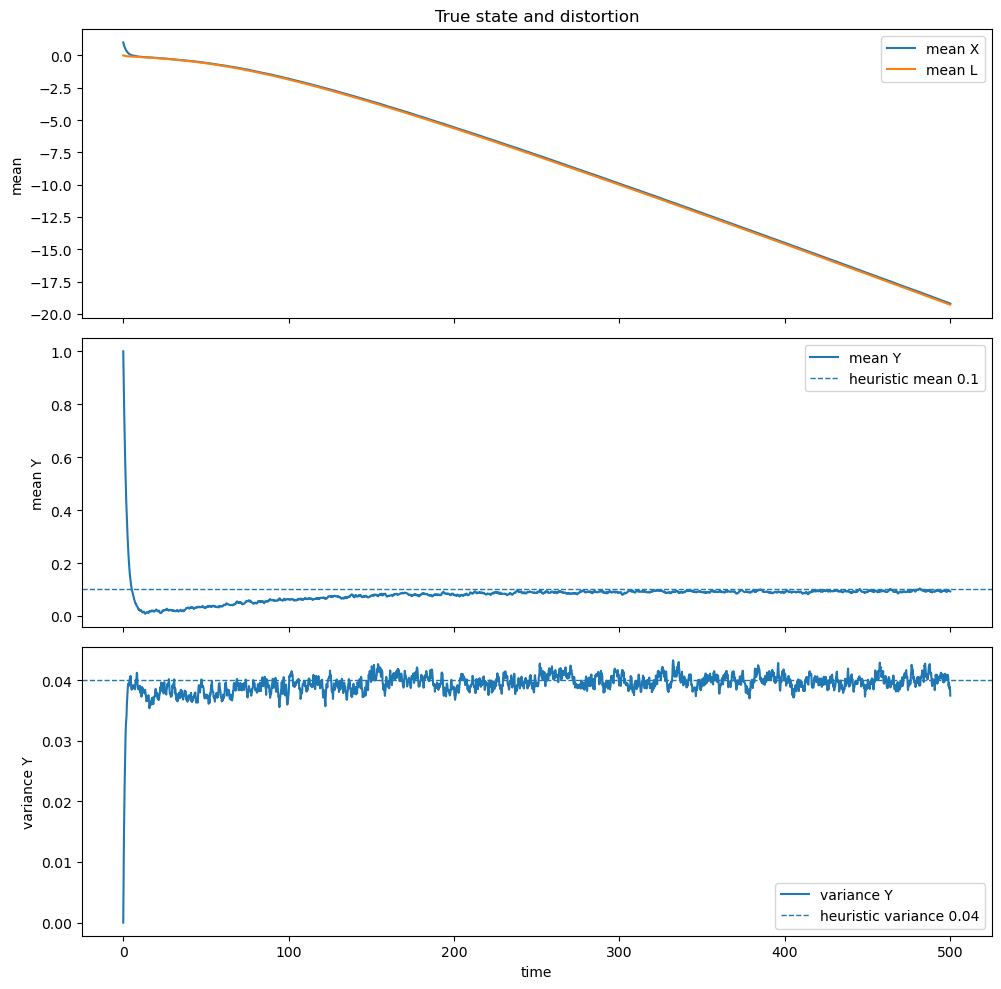

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.2\result images\hw8_2\part6_long_time_behavior.png


In [7]:
fig, axes = plt.subplots(
    3,
    1,
    figsize=(10, 10),
    sharex=True,
)

axes[0].plot(
    long_summary[
        "t"
    ],
    long_summary[
        "mean_X"
    ],
    label="mean X",
)

axes[0].plot(
    long_summary[
        "t"
    ],
    long_summary[
        "mean_L"
    ],
    label="mean L",
)

axes[0].legend()
axes[0].set_ylabel("mean")
axes[0].set_title(
    "True state and distortion"
)

axes[1].plot(
    long_summary[
        "t"
    ],
    long_summary[
        "mean_Y"
    ],
    label="mean Y",
)

axes[1].axhline(
    REFERENCE_PREDICTIONS[
        "late_y_mean"
    ],
    linestyle="--",
    linewidth=1.0,
    label="heuristic mean 0.1",
)

axes[1].legend()
axes[1].set_ylabel("mean Y")

axes[2].plot(
    long_summary[
        "t"
    ],
    long_summary[
        "variance_Y"
    ],
    label="variance Y",
)

axes[2].axhline(
    REFERENCE_PREDICTIONS[
        "late_y_variance"
    ],
    linestyle="--",
    linewidth=1.0,
    label="heuristic variance 0.04",
)

axes[2].legend()
axes[2].set_ylabel("variance Y")
axes[2].set_xlabel("time")

plt.tight_layout()

path = (
    RESULT_DIR
    / "part6_long_time_behavior.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print(
    "Saved:",
    path.resolve(),
)

## Audit checklist

After the independent response has been pasted, evaluate it against the following facts.

### State distinction

The true state is $X_t$.

The distortion is $L_t$.

The perceived state is

$$
Y_t=X_t-L_t.
$$

### Brownian noise

The independent Brownian term enters directly only through $X_t$.

$L_t$ is still random because its drift depends on the random process $X_t$.

### Fokker-Planck equation

The joint equation is

$$
\frac{\partial p}{\partial t}
=
-\frac{\partial}{\partial x}
\left[
a(-x+\ell)p
\right]
-
\frac{\partial}{\partial \ell}
\left[
-\kappa
\frac{|x|}
{1+\eta|\ell|}
p
\right]
+
\frac{\sigma^2}{2}
\frac{\partial^2p}{\partial x^2}.
$$

### Reconstruction

With exact full-path $Y$, known parameters, and known $L_0$, the hidden state is determined by the ODE for $L$.

Unknown $L_0$, sparse observations, or sensor noise create an inference problem and residual uncertainty.

### Long-time claims

Finite-time numerical agreement with the heuristic quantities does not by itself prove a mathematical asymptotic theorem.

The audit must separate:

- what the LLM predicted;
- what the simulations show on the finite horizon;
- what has actually been proved.

# Part VI Audit Conclusion

The LLM response passes the four structural checks required by the assignment:

1. It distinguishes the true state $X_t$, distortion $L_t$, and perceived state $Y_t=X_t-L_t$.
2. It correctly places the independent Brownian noise only in the $X_t$ equation while recognizing that $L_t$ is still random through its drift.
3. It gives the correct joint Fokker-Planck equation, including diffusion only in the $x$ direction.
4. It correctly distinguishes exact-path reconstruction with known $L_0$ from statistical inference when $L_0$ is unknown or observations are sparse or noisy.

The fresh holdout simulation is also consistent with the quantitative long-time heuristic. Over the latest window $[400,500]$:

- predicted growth rate of $U_t=-L_t$: $0.0500$; simulated slope: $0.04694$;
- predicted mean of $Y_t$: $0.1000$; simulated average: $0.09306$;
- predicted variance of $Y_t$: $0.0400$; simulated average: $0.03984$.

The simulated slope and mean move toward the heuristic values as the fitting window is shifted later in time. This is finite-time numerical evidence, not a proof that these limits hold as $t$ goes to infinity.

At $t=500$, the ensemble means are approximately

$$
E[X_{500}] = -19.199,
$$

$$
E[L_{500}] = -19.292,
$$

while

$$
E[Y_{500}] = 0.0926.
$$

Thus the perceived state can look statistically stable even though the hidden pair is not stable and drifts to large negative values. That distinction is the most important conclusion of the LLM audit.
